# Check convergence 

In [1]:
import cobra
import pandas as pd
import numpy as np
from os import listdir
import warnings
import seaborn as sns
from collections import OrderedDict
import json
import os
import matplotlib.pyplot as plt
import math



from reframed.community.model import Community
from reframed import Environment, set_default_solver
from steadiercom.cli import load_communities,load_media_db

In [2]:
import seaborn as sns

In [3]:
import sys

sys.path.append("../functions/")
from convergence import SteadierSampleConvergence

In [4]:
%load_ext autoreload
%autoreload 2

### Gut microbiome community

Concentration $X_0$ (right after serial transfer) and $X_1$ (right before next transfer) in $t_0$ and $t_1$

$$
X_1 = X_0 *e^{\mu t_1} , X_0 = X_0
$$

Assuming that the cells grow back to the original concentration (after being diluted 1:20 => the cells increase in density by 21 times)

$$
X_1/X_0 = 21 = e^{\mu t} 
$$

The above equation turns into:
$$
ln(X_1/X_0) = \mu t
$$

Which means the avearage growth rate becomes
$$
\mu_{avg} = \frac{ln(21)}{t}
$$

**Methods (From Venturelli et al. 2018): 1:20 dilution every 24 h**

In [5]:
np.log(21)/24

np.float64(0.1268551015718093)

In [6]:
mediadb = "../data/Venturelli2018/generated/media_db.tsv"#path to mediadb
medium = "LB_extend"
growth = np.log(21)/24# average growth rate

models = ["../models/Venturelli2018/species_used/"+name for name in listdir("../models/Venturelli2018/species_used_noO2/")]
communities = "../data/Venturelli2018/generated/communities_steadiercom/NONE_abundance.tsv"

comm_id = "NONE"

output_dir = "../output/Venturelli2018/convergence_test/"

In [7]:
direct = os.listdir("../output/Venturelli2018/convergence_test/")

dfs = []
for d in direct:
    if d.endswith(".tsv"):
        df = pd.read_csv("../output/Venturelli2018/convergence_test/"+str(d),sep="\t",index_col=(0,1))
        dfs.append(df)

dfs_tot = pd.concat(dfs,axis=1)

dfs_tot = dfs_tot.T.drop_duplicates().T

dfs_tot.columns = np.arange(0,dfs_tot.shape[1])
dfs_tot = dfs_tot.fillna(0)


### Plotting coefficient of variance based on sample size

The x-axis shows the number of samples in each set. The y-axis shows the coefficient of variance across all sets of the same size. We expect a higher number of samples in each set to cover more alternative optima and thereby reduce the variance between sets.

We see that there is lower variance between sets when their sample size is large.

In [8]:
statistics = {}
datas = {}
for n in np.logspace(1,3.6,25):
    sample_size = int(n)

    number = math.floor(dfs_tot.shape[1]/sample_size)
    data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


    equal_zero= data.sum(axis=1).apply(abs).sort_values() <1e-3 # Cutoff based on when the solution is more stable
    data = data.loc[~equal_zero]
    
    cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
    data = data.T.apply(cv)
    datas[sample_size]=data    
    
    median = data.median()
    mean = data.mean()
    max_ = data.max()
    min_ = data.min()
    statistics[sample_size] = {"mean":mean,
                               "median":median,
                               "max":max_,
                               "min":min_}

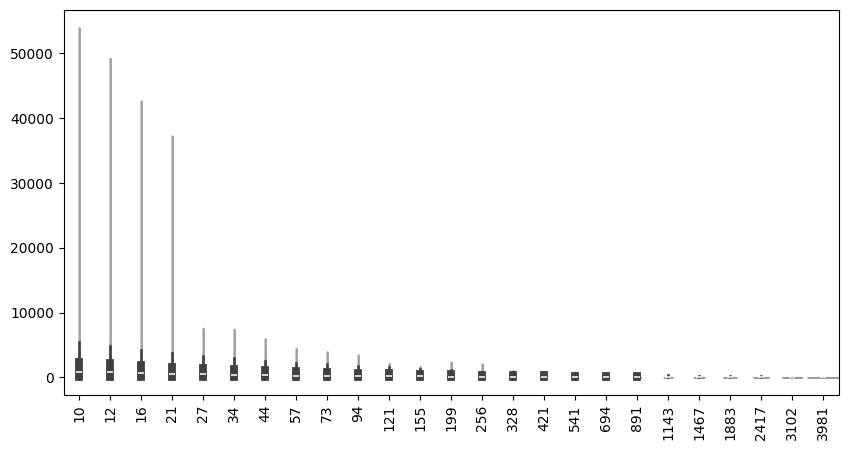

In [9]:
fig = plt.figure(figsize =(10, 5))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas),cut=0,ax=ax, color="blue",alpha=0.5,width=1.0)
ticks = plt.xticks(rotation=90)

(0.0, 300.0)

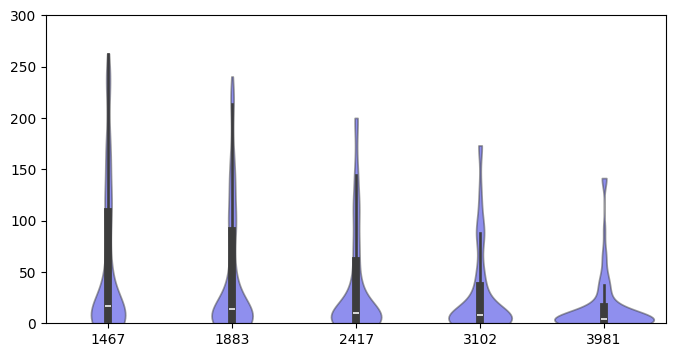

In [10]:


fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas).iloc[:,-5:],cut=0,ax=ax,color="blue",alpha=0.5)
ax.set_ylim([0,300])

### Plotting coefficient of variance based on average flux rate and sample size

The x-axis represent the range of average flux rate across different sets (example: flux is between 1e-6 and 3e-6). The y-axis represents the coefficient of variance. 

We see that when the average flux is higher the coefficient of variance is lower.

In [11]:
statistics = {}

for n in [100,250,500,800,1000,1200,1500,3000]:
    b = -6
    
    statistics[n]={}
    for a in np.linspace(-5.5,1,14):

        sample_size = int(n)
        number = math.floor(dfs_tot.shape[1]/sample_size)


        data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})

        data_set_lower= data.mean(axis=1).apply(abs).sort_values() <10**(a)
        data_set_upper = data.mean(axis=1).apply(abs).sort_values() >10**(b)
        data_bound = data_set_lower * data_set_upper
        data = data.loc[data_bound]

        cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
        data = data.T.apply(cv)


        median = data.median()

        statistics[n][(round(10**b,6),round(10**a,6))] =median
        b=a

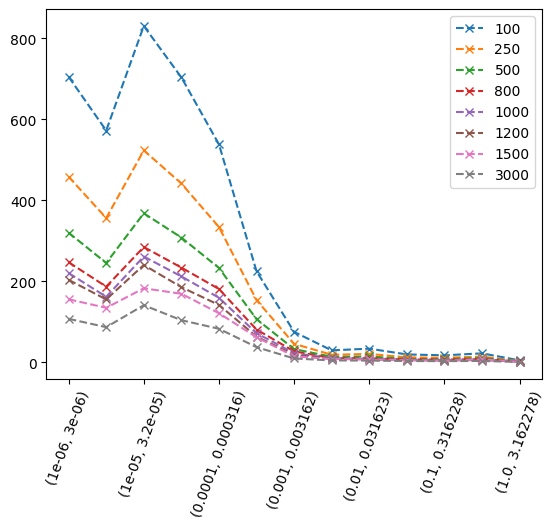

In [12]:
pd.DataFrame(statistics).plot(marker="x",linestyle="--")
xticks = plt.xticks(rotation=70)

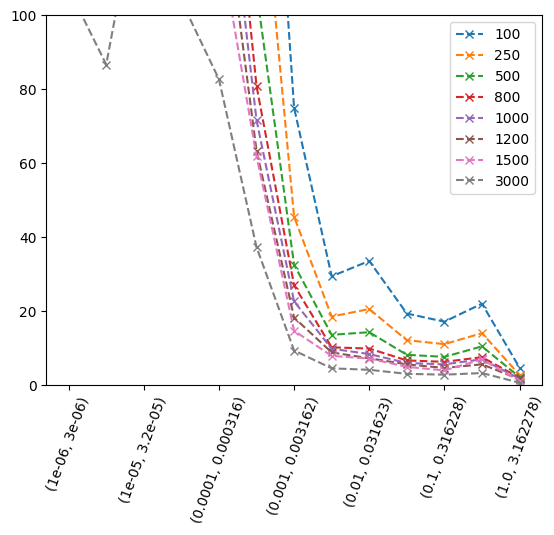

In [13]:
pd.DataFrame(statistics).plot(marker="x",linestyle="--",ylim=[0,100])
xticks = plt.xticks(rotation=70)

### Plotting coefficient of variance based on average flux rate, sample size, and frequency

The x-axis represent the range of frequency of an observation across different sets (example: a compound is shared in 0.0 and 0.05 of the solutions). The y-axis represents the coefficient of variance based on flux rate.. 

We see that when the frequency is higher the coefficient of variance is lower.

In [14]:
statistics = {}
data = None

for n in [100, 250, 500, 800, 1000,1200, 1500, 3000]:
    a = 0
    statistics[n] = {}

    for b in np.linspace(0.05, 1, 20):
        # Calculate possible number of non-overlapping sets
        sample_size = int(n)
        number = math.floor(dfs_tot.shape[1] / sample_size)

        mean_data = {}
        freq_data = {}

        for i in range(number):
            # Get samples of a given sample size
            subset = dfs_tot.iloc[:, i * sample_size: (i + 1) * sample_size]

            # Mean per feature across this sample set
            mean_data[f"set{i}"] = subset.T.mean()

            # Frequency of non-zero entries per feature in this sample set
            freq_data[f"set{i}"] = (subset!=0).T.sum() / sample_size

        mean_df = pd.DataFrame(mean_data)
        freq_df = pd.DataFrame(freq_data)

        # Mean frequency across sets per feature
        freq_mean = freq_df.mean(axis=1)

        # Select only features with frequency between a and b
        selected_features = freq_mean[(freq_mean > a) & (freq_mean < b)].index

        # Subset the data
        filtered_mean_df = mean_df.loc[selected_features]

        # Coefficient of variation (CV)
        cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100
        data = filtered_mean_df.T.apply(cv)

        median = data.median()
        statistics[n][( round(a, 4),round(b, 4))] = median
        a = b

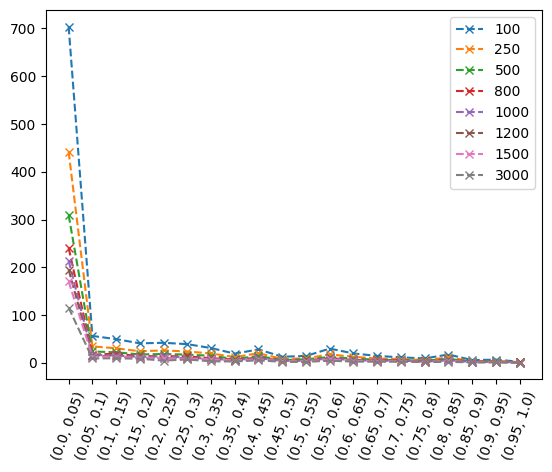

In [15]:
ax = pd.DataFrame(statistics).plot(marker="x",linestyle="--")
ax.set_xticks(np.arange(len(pd.DataFrame(statistics).index)))
labels = ax.set_xticklabels(pd.DataFrame(statistics).index)
xticks = plt.xticks(rotation=70)



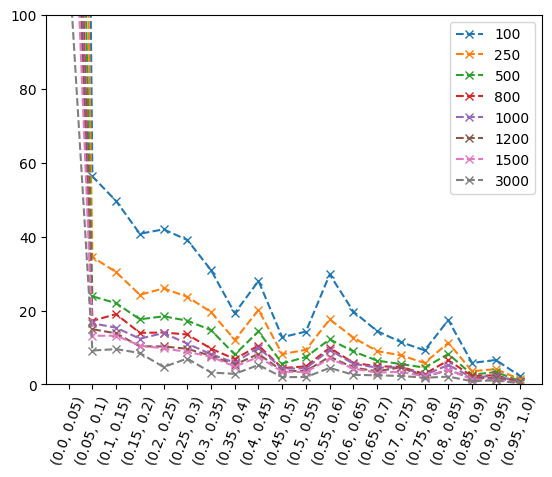

In [16]:
ax = pd.DataFrame(statistics).plot(marker="x",linestyle="--",ylim=[0,100])
ax.set_xticks(np.arange(len(pd.DataFrame(statistics).index)))
labelsx = ax.set_xticklabels(pd.DataFrame(statistics).index)

xticks = plt.xticks(rotation=70)



## E.coli mutants community

Concentration $X_0$ (right after serial transfer) and $X_1$ (right before next transfer) in $t_0$ and $t_1$

$$
X_1 = X_0 *e^{\mu t_1} , X_0 = X_0
$$

Assuming that the cells grow back to the original concentration (after being diluted 5:995 => has to increase 200 times)

$$
X_1/X_0 = 200 = e^{\mu t} 
$$

The above equation turns into:
$$
ln(X_1/X_0) = \mu t
$$

Which means the avearage growth rate becomes
$$
\mu_{avg} = \frac{ln(200)}{t}
$$

**Methods (From Guillen et al. 2021): 1:200 dilution every 24 h**

In [17]:
np.log(200)/24

np.float64(0.22076322360616818)

**Input data**

In [18]:
mediadb = "../data/Guillen2021/generated/media_db.tsv"#path to mediadb
media = ["M9"]
growth = np.log(200)/24 

models = ["../models/Guillen2021/top_7_strains/"+name for name in listdir("../models/Guillen2021/top_7_strains/")]
communities = "../data/Guillen2021/generated/communities_steadiercom.tsv"

comm_id = "Ecoli_mutants"

output_dir = "../output/Guillen2021/convergence_test/"

**Run SteadierSample**

**Load SteadierSample results**

In [21]:
direct = os.listdir("../output/Guillen2021/convergence_test/")

dfs = []
for d in direct:
    if d.endswith(".tsv"):
        df = pd.read_csv("../output/Guillen2021/convergence_test/"+str(d),sep="\t",index_col=(0,1))
        dfs.append(df)

dfs_tot = pd.concat(dfs,axis=1)

dfs_tot = dfs_tot.T.drop_duplicates().T

dfs_tot.columns = np.arange(0,dfs_tot.shape[1])
dfs_tot = dfs_tot.fillna(0)


### Plotting coefficient of variance based on sample size

The x-axis shows the number of samples in each set. The y-axis shows the coefficient of variance across all sets of the same size. We expect a higher number of samples in each set to cover more alternative optima and thereby reduce the variance between sets.

We see that there is lower variance between sets when their sample size is large.

In [32]:
statistics = {}
datas = {}
for n in np.logspace(1,3.8,25):
    sample_size = int(n)

    number = math.floor(dfs_tot.shape[1]/sample_size)
    data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


    equal_zero= data.sum(axis=1).apply(abs).sort_values() <1e-3 #Cutoff set to same value as for the gut microbiome
    data = data.loc[~equal_zero]
    
    cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
    data = data.T.apply(cv)
    datas[sample_size]=data    
    
    median = data.median()
    mean = data.mean()
    max_ = data.max()
    min_ = data.min()
    statistics[sample_size] = {"mean":mean,
                               "median":median,
                               "max":max_,
                               "min":min_}

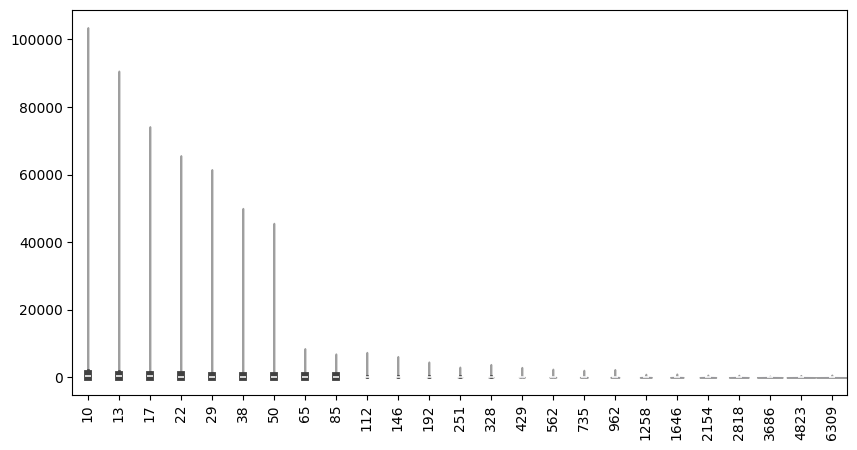

In [33]:
fig = plt.figure(figsize =(10, 5))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas),cut=0,ax=ax, color="blue",alpha=0.5,width=1.0)
ticks = plt.xticks(rotation=90)

(0.0, 1000.0)

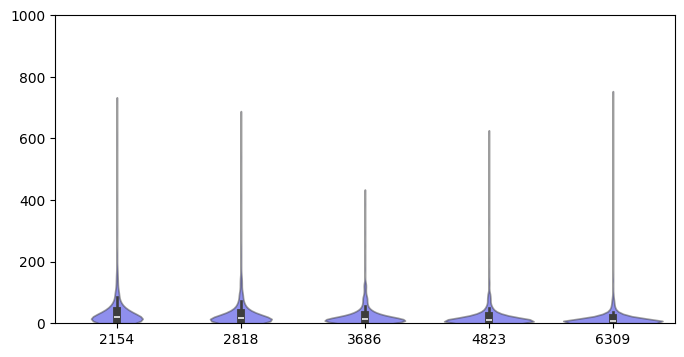

In [34]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas).iloc[:,-5:],cut=0,ax=ax,color="blue",alpha=0.5)
ax.set_ylim([0,1000])

### Plotting coefficient of variance based on average flux rate and sample size

The x-axis represent the range of average flux rate across different sets (example: flux is between 1e-6 and 3e-6). The y-axis represents the coefficient of variance. 

We see that when the average flux is higher the coefficient of variance is lower.

In [35]:
statistics = {}

for n in [100,250,500,800,1000,1200,1500,3000,4000,5000,6000,7000]:
    b = -6
    
    statistics[n]={}
    for a in np.linspace(-5.5,1,14):

        sample_size = int(n)
        number = math.floor(dfs_tot.shape[1]/sample_size)


        data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})

        data_set_lower= data.mean(axis=1).apply(abs).sort_values() <10**(a)
        data_set_upper = data.mean(axis=1).apply(abs).sort_values() >10**(b)
        data_bound = data_set_lower * data_set_upper
        data = data.loc[data_bound]

        cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
        data = data.T.apply(cv)


        median = data.median()

        statistics[n][(round(10**b,6),round(10**a,6))] =median
        b=a

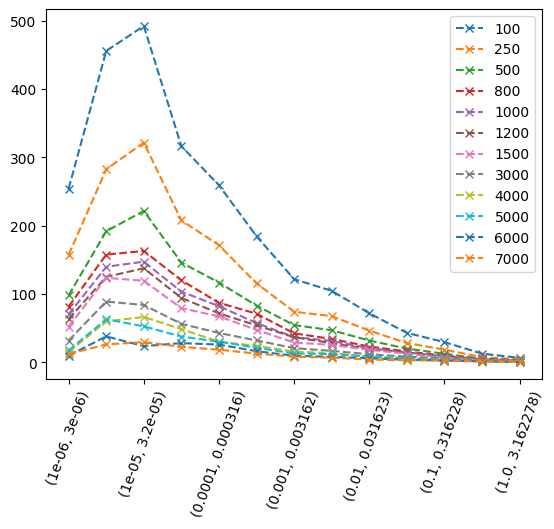

In [36]:
pd.DataFrame(statistics).plot(marker="x",linestyle="--")
xticks = plt.xticks(rotation=70)

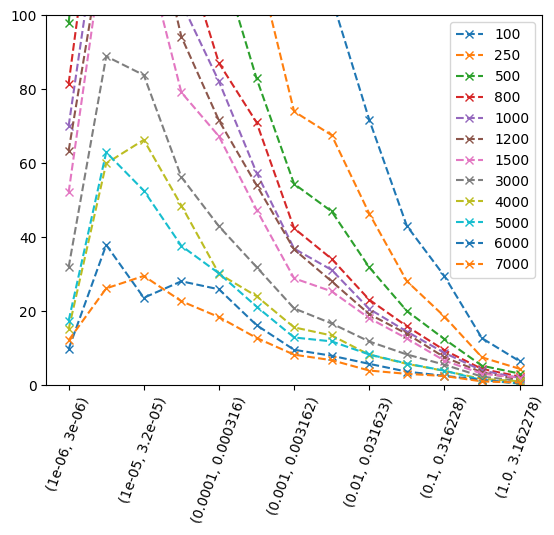

In [37]:
pd.DataFrame(statistics).plot(marker="x",linestyle="--",ylim=[0,100])
xticks = plt.xticks(rotation=70)

### Plotting coefficient of variance based on average flux rate, sample size, and frequency

The x-axis represent the range of frequency of an observation across different sets (example: a compound is shared in 0.0 and 0.05 of the solutions). The y-axis represents the coefficient of variance based on flux rate.. 

We see that when the frequency is higher the coefficient of variance is lower.

**NB: This function takes the average of both production and consumption...**

In [28]:
statistics = {}
data = None

for n in [100, 250, 500, 800, 1000,1200, 1500, 3000,4000,5000,6000,7000]:
    a = 0
    statistics[n] = {}

    for b in np.linspace(0.05, 1, 20):
        # Calculate possible number of non-overlapping sets
        sample_size = int(n)
        number = math.floor(dfs_tot.shape[1] / sample_size)

        mean_data = {}
        freq_data = {}

        for i in range(number):
            # Get samples of a given sample size
            subset = dfs_tot.iloc[:, i * sample_size: (i + 1) * sample_size]

            # Mean per feature across this sample set
            mean_data[f"set{i}"] = subset.T.mean()

            # Frequency of non-zero entries per feature in this sample set
            freq_data[f"set{i}"] = (subset!=0).T.sum() / sample_size

        mean_df = pd.DataFrame(mean_data)
        freq_df = pd.DataFrame(freq_data)

        # Mean frequency across sets per feature
        freq_mean = freq_df.mean(axis=1)

        # Select only features with frequency between a and b
        selected_features = freq_mean[(freq_mean > a) & (freq_mean < b)].index

        # Subset the data
        filtered_mean_df = mean_df.loc[selected_features]

        # Coefficient of variation (CV)
        cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100
        data = filtered_mean_df.T.apply(cv)

        median = data.median()
        statistics[n][( round(a, 4),round(b, 4))] = median
        a = b

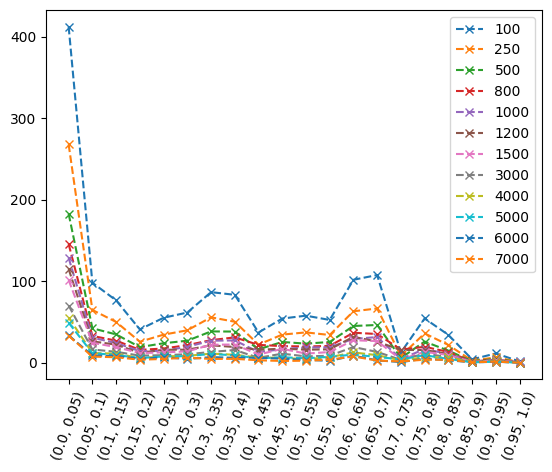

In [29]:
ax = pd.DataFrame(statistics).plot(marker="x",linestyle="--")
ax.set_xticks(np.arange(len(pd.DataFrame(statistics).index)))
labels = ax.set_xticklabels(pd.DataFrame(statistics).index)
xticks = plt.xticks(rotation=70)



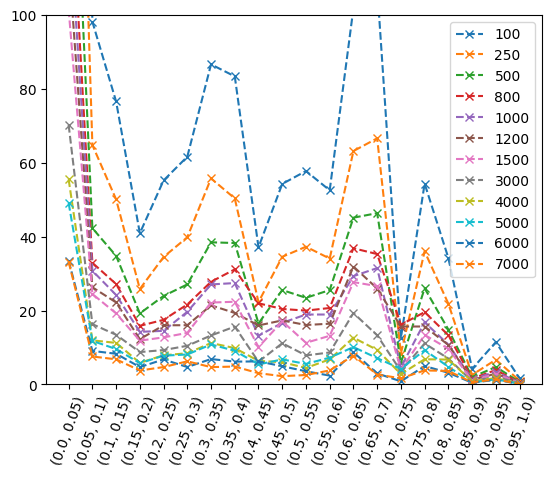

In [30]:
ax = pd.DataFrame(statistics).plot(marker="x",linestyle="--",ylim=[0,100])
ax.set_xticks(np.arange(len(pd.DataFrame(statistics).index)))
labelsx = ax.set_xticklabels(pd.DataFrame(statistics).index)

xticks = plt.xticks(rotation=70)

